# Estudo do Perceptron com Scikit-Learn

Neste notebook, vamos explorar o funcionamento do **perceptron**, um dos modelos fundamentais de Machine Learning.

Utilizando a biblioteca Scikit-Learn, vamos treinar um perceptron para resolver um problema de classificação, analisando como o modelo ajusta seus pesos para distinguir diferentes classes.

Ao longo do estudo, veremos como criar dados artificiais para o treinamento, treinar o modelo, interpretar os pesos e o viés aprendidos, visualizar a fronteira de decisão e avaliar o desempenho das classificações.

O objetivo é compreender, na prática, como funciona um classificador linear e quais são suas capacidades e limitações, construindo uma base para o estudo de redes neurais mais complexas.

Text(0, 0.5, 'Característica 2')

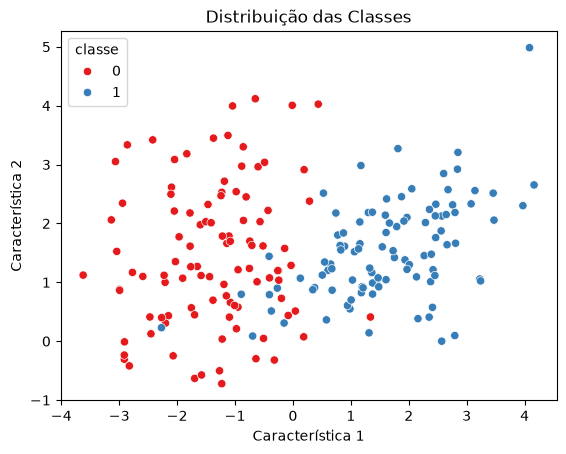

In [ ]:
from sklearn.datasets import make_classification
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# Cria dados artificiais com 2 features e cada classe com 1 cluster
x,y = make_classification(
    n_samples=200,n_features=2,
    n_informative=2,n_redundant=0,
    n_clusters_per_class=1,class_sep=1.5,
    random_state=42
)
# ADiciona os dados no dataFrame
df = pd.DataFrame(x,columns=["x1","x2"])
df["classe"] = y
#Plota os dados usando seaborn
sns.scatterplot(data=df,x="x1",y="x2",hue="classe",palette="Set1")
plt.title("Distribuição das Classes")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")





### Treinamento do Modelo
Após a visualização inicial das classes com Seaborn, os dados são divididos em conjuntos de treinamento (80%) e teste (20%). Em seguida, o modelo é treinado por 191 épocas, com taxa de aprendizado de 0,1.

Ao final de cada época, os pesos e o viés do modelo são armazenados em listas, permitindo acompanhar sua evolução e utilizá-la na animação desenvolvida com Manim. Por fim, o modelo realiza previsões sobre os dados de teste, e seu desempenho é avaliado por meio da acurácia e da matriz de confusão.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix

#Separa os dados gerados em dados de treino e de teste
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
#Cria e treina o perceptron com taxa de aprendizado sendo 0.1
perc = Perceptron(eta0=0.1,random_state=42,warm_start=True,max_iter=1,tol=None)

historico_pesos = []
historico_bias = []

for epoca in range(191):
    perc.fit(x_train,y_train)
    historico_pesos.append(perc.coef_[0].copy())
    historico_bias.append(perc.intercept_[0])


y_pred = perc.predict(x_test)
#Retorna principais informações sobre a predição do perceptron
print("Pesos:", perc.coef_)
print("Viés:", perc.intercept_)
print("Acurácia:", accuracy_score(y_test, y_pred))
print("Matriz de confusão:\n", confusion_matrix(y_test, y_pred))


Pesos: [[ 0.40698791 -0.13166491]]
Viés: [0.2]
Acurácia: 0.9
Matriz de confusão:
 [[19  4]
 [ 0 17]]


### Função que determina a fronteira

O modelo utiliza a seguinte função para determinar a fronteira entre as classes:

$$
h(x) = w_1x_1 + w_2x_2 + b
$$.

O peso de cada feature indica a sua influência para a determinação da fronteira. Substituindo os valores encontrados temos:

$$
h(x) = 0.41x_1 - 0.13 x_2 + 0.2
$$.

### Matriz de Confusão

Analisando a matriz de confusão, concluímos que de 40 casos de teste conseguimos classificar 36 corretamente. Esse resultado indica uma acurácia de 90%. Os erros de classificação ocorreram apenas para a classe 0 para o teste aplicado.

(-1.2219982178951807, 5.484225810401386)

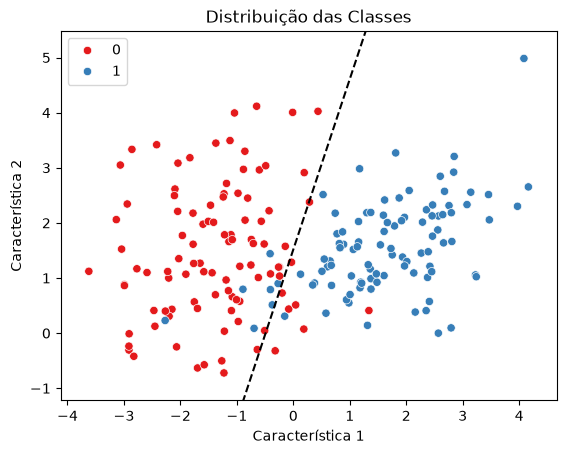

In [ ]:
import numpy as np

#Adiciona a reta encontrada para dividir as classes
w1,w2 = perc.coef_[0]
b = perc.intercept_[0]
x1 = np.linspace(x[:,0].min(),x[:,0].max(),100)
x2 = -(w1 * x1 + b) / w2

sns.scatterplot(data=df,x="x1",y="x2",hue="classe",palette="Set1")
plt.title("Distribuição das Classes")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
sns.lineplot(x=x1, y=x2, color="black", linestyle="--")
plt.xlim(x[:, 0].min() - 0.5, x[:, 0].max() + 0.5)
plt.ylim(x[:, 1].min() - 0.5, x[:, 1].max() + 0.5)


In [ ]:
from manim import *
from manim.utils.ipython_magic import ManimMagic
from IPython import get_ipython

ip = get_ipython()
ip.register_magics(ManimMagic)

In [ ]:
%%manim -ql -v WARNING AnimacaoPerceptron

from manim import *
import numpy as np

def modelo(plano,xmin,xmax,w1,w2,b):
    if abs(w2) > 1e-8:
        return plano.plot(
            lambda z: -(w1 * z + b) / w2,
            x_range=[xmin, xmax],
            color=WHITE,
            stroke_width=4,
        )
    return None

def wrong_line_animation(self,reta):
    if reta is not None:
        self.play(Create(reta), run_time=2)
        self.play(
            reta.animate.set_color(RED),
        )
        self.play(
            Wiggle(reta,scale_value=1.01,rotation_angle=0.02,run_time=1.5)
        )
        self.play(
            FadeOut(reta),
            run_time =  0.5
        )

def right_line_animation(self,reta):
    if reta is not None:
        self.play(Create(reta), run_time=2)
        self.play(
            reta.animate.set_color(GOLD),
        )

class AnimacaoPerceptron(Scene):
    def construct(self):
        # Usa os dados e o modelo já criados no notebook

        
        

        # Limites do plano cartesiano
        xmin, xmax = x[:, 0].min() - 0.5, x[:, 0].max() + 0.5
        ymin, ymax = x[:, 1].min() - 0.5, x[:, 1].max() + 0.5

        plano = Axes(
            x_range=[xmin, xmax, 2],
            y_range=[ymin, ymax, 2],
            x_length=10,
            y_length=5.5,
            axis_config={"include_numbers": True},
            tips=False,
        ).to_edge(DOWN, buff=0.6)

        titulo = Text(
            "Classificacao com Perceptron",
            font_size=30
        ).to_edge(UP, buff=0.2)

        self.play(Write(titulo), Create(plano))

        # Cria um ponto para cada observacao
        pontos = VGroup()

        for xi, yi in zip(x, y):
            cor = RED if yi == 0 else BLUE
            ponto = Dot(
                plano.c2p(xi[0], xi[1]),
                radius=0.055,
                color=cor
            )
            pontos.add(ponto)

        # Mostra os pontos gradualmente
        self.play(
            LaggedStart(
                *[FadeIn(p) for p in pontos],
                lag_ratio=0.01
            ),
            run_time=3
        )

        # Calcula e desenha As fronteiras intermediarias e a final
        w1, w2 = historico_pesos[0]
        b = historico_bias[0]
        reta = modelo(plano,xmin,xmax,w1,w2,b)
        wrong_line_animation(self,reta)
        
        w1, w2 = historico_pesos[100]
        b = historico_bias[100]
        reta = modelo(plano,xmin,xmax,w1,w2,b)
        wrong_line_animation(self,reta)
        
        w1, w2 = perc.coef_[0]
        b = perc.intercept_[0]
        reta = modelo(plano,xmin,xmax,w1,w2,b)
        right_line_animation(self,reta)
        
        # Legenda
        legenda = VGroup(
            VGroup(Dot(color=RED), Text("Classe 0", font_size=20)).arrange(RIGHT),
            VGroup(Dot(color=BLUE), Text("Classe 1", font_size=20)).arrange(RIGHT),
            VGroup(Dot(color=GOLD), Text("Fronteira", font_size=20)).arrange(RIGHT),
        ).arrange(RIGHT, buff=0.35).to_edge(UP, buff=0.8)

        self.play(FadeIn(legenda))

        # Equacao aprendida pelo modelo
        equacao = Text(
            rf"{w1:.2f}x1 {w2:+.2f}x2 {b:+.2f} = 0",
            font_size=30
        ).to_edge(DOWN, buff=0.1)

        self.play(Write(equacao))
        self.wait(3)


Manim Community v0.22.0